# Стадия 4. Полиномиальные признаки и регуляризация

**Данные:** синтетический датасет на основе клинического исследования цирроза печени
(публикация Kaggle `playground-series-s3e26`, первоисточник — UCI Cirrhosis, описание — `README.md`).
**Предыдущие этапы:** `Stage_1_analysis.ipynb` — анализ данных и отбор 15 признаков;
`Stage_2_regression.ipynb` — почему не подходит оценка по числу;
`Stage_3_classification.ipynb` — логистическая регрессия, порог по цене ошибки и калибровка.

**Цель стадии.** Проверить, можно ли поднять качество модели, усложнив её двумя способами сразу:
добавив **полиномиальные признаки** (квадраты и произведения отобранных показателей) и включив
**регуляризацию**, которая не даёт этой сложности превратиться в переобучение.

**Цель — бинарная.** Модель предсказывает `Event`: 0 — пациент жив со своей печенью, 1 — трансплантация или смерть. Один вектор коэффициентов вместо трёх, одна вероятность вместо распределения по классам.

**Опорные числа стадии 3.** ROC-AUC **0.8788**, PR-AUC 0.8132, метрика Брайера 0.1333, лог-потеря **0.4257**, F-мера 0.7307, доля верных ответов 0.8128 на контрольной части. Любой вариант этой стадии сравнивается с ними.

**Почему полиномы.** Линейная модель проводит между классами прямую границу. Если влияние
показателя не линейно — например, риск резко растёт после определённого уровня билирубина, —
прямая этого не передаст. Квадрат признака и произведения пар признаков дают модели возможность
изогнуть границу, оставаясь линейной по коэффициентам.

**Почему регуляризация.** Число новых столбцов растёт быстро: 15 признаков дают 135 столбцов
второй степени и 815 третьей. На 5 928 обучающих строках такая матрица легко «запоминается»
целиком: начинается переобучение. Штраф за большие коэффициенты возвращает модель к разумной
сложности.

**Что берём в работу.** Ту же матрицу из **15 признаков** (`train_model.parquet`, блок 3.14
стадии 1) и то же разбиение 75/25 со стратификацией и `RANDOM_STATE = 42`. Состав признаков
не меняется: полиномиальные столбцы — производные от тех же 15 показателей, а не новые данные.


## **1. Импорты и настройки**

In [1]:
# Сторонние библиотеки
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,
                             confusion_matrix, f1_score, log_loss,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict,
                                     train_test_split)
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

# Единое зерно случайности для всего ноутбука: выборки, разбиения, кросс-валидация.
# Значение не меняется между прогонами и стадиями, поэтому результаты сравнимы.
RANDOM_STATE = 42


## **2. Загрузка данных**

Данные берутся из `data/processed/train_model.parquet` — итогового набора стадии 1: 15 признаков
и бинарная цель `Event`, 7 905 строк. Форма файла проверяется `assert`: стадия 4 ничего не должна
менять в контракте данных.


In [2]:
# Корень проекта: папка с data/, найденная вверх по дереву от текущей директории
def find_project_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isdir(os.path.join(d, 'data')):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            raise FileNotFoundError('Папка data/ не найдена вверх по дереву от ' + d)
        d = parent


PROJECT_ROOT = find_project_root()
df = pd.read_parquet(os.path.join(PROJECT_ROOT, 'data', 'processed', 'train_model.parquet'))
print(f'Строк: {len(df)}, столбцов: {df.shape[1]} (15 признаков + цель)')
assert df.shape == (7905, 16), 'Ожидается матрица 7 905 x 16 из стадии 1'
assert df.isna().sum().sum() == 0, 'В матрице модели не должно быть пропусков'
assert set(df['Event'].unique()) == {0, 1}, 'Цель должна быть бинарной: 0 и 1'
df.head(3)


Строк: 7905, столбцов: 16 (15 признаков + цель)


,log_Bilirubin,log_Copper,log_Alk_Phos,log_SGOT,log_Cholesterol,log_Tryglicerides,Albumin,Platelets,Prothrombin,Age_years,Stage,Edema_num,Sex_M,Hepatomegaly_Y,Spiders_Y,Event
0,1.193922,5.153292,7.379008,5.197391,5.758902,4.158883,3.35,394.0,9.7,59.0,3.0,0.0,1,0,0,1
1,0.641854,4.158883,7.273093,4.911551,5.899897,4.488636,3.54,361.0,11.0,52.7,3.0,0.0,0,0,0,0
2,1.458615,4.882802,6.937314,4.790404,5.703782,3.931826,3.55,199.0,11.7,37.6,4.0,1.0,0,1,1,1


### Точка отсчёта: повтор базовой модели стадии 3

Прежде чем что-то усложнять, воспроизведём базовую модель стадии 3 и **сверим её метрики
с записанными в стадии 3**. Это не формальность: если разбиение, стандартизация или версия
библиотеки дадут другие числа, все дальнейшие сравнения потеряют смысл.

Разбиение и предобработка повторяются дословно: 75/25, `stratify=y`, `RANDOM_STATE = 42`,
`StandardScaler` обучается только на train.


In [3]:
X = df.drop(columns=['Event']).astype(float)
y = df['Event'].astype(int)
assert X.shape[1] == 15, 'В матрице должно быть 15 отобранных признаков'

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_tr = scaler.fit_transform(X_train)   # fit только на train
X_te = scaler.transform(X_test)

print('Размеры выборок:', X_tr.shape[0], 'train /', X_te.shape[0], 'test')
print('Событий в контрольной части:', int(y_test.sum()), 'из', len(y_test))


def evaluate(model, X_eval, y_eval, tag, threshold=0.5):
    # Считает набор метрик бинарной классификации и возвращает строку для сводной таблицы.
    y_proba = model.predict_proba(X_eval)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)
    return {
        'вариант': tag,
        'ROC-AUC': roc_auc_score(y_eval, y_proba),
        'PR-AUC': average_precision_score(y_eval, y_proba),
        'метрика Брайера': brier_score_loss(y_eval, y_proba),
        'лог-потеря': log_loss(y_eval, y_proba),
        'F-мера': f1_score(y_eval, y_pred),
        'полнота': recall_score(y_eval, y_pred),
        'точность': precision_score(y_eval, y_pred),
        'доля верных ответов': accuracy_score(y_eval, y_pred),
    }


base_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
base_model.fit(X_tr, y_train)

results = [evaluate(base_model, X_te, y_test, 'базовая (стадия 3)')]

# Сверка со стадией 3: те же строки, то же разбиение, та же модель
STAGE3_REFERENCE = {
    'ROC-AUC': 0.8788,
    'PR-AUC': 0.8132,
    'метрика Брайера': 0.1333,
    'лог-потеря': 0.4257,
    'F-мера': 0.7307,
    'полнота': 0.6830,
    'точность': 0.7856,
    'доля верных ответов': 0.8128,
}
for metric, expected in STAGE3_REFERENCE.items():
    actual = results[0][metric]
    assert abs(actual - expected) < 5e-4, f'{metric}: {actual:.4f} против {expected} в стадии 3'
print('Метрики совпали со стадией 3 — разбиение и предобработка идентичны.')
display(pd.DataFrame(results).set_index('вариант').round(4))


Размеры выборок: 5928 train / 1977 test
Событий в контрольной части: 735 из 1977
Метрики совпали со стадией 3 — разбиение и предобработка идентичны.


,ROC-AUC,PR-AUC,метрика Брайера,лог-потеря,F-мера,полнота,точность,доля верных ответов
вариант,,,,,,,,
базовая (стадия 3),0.8788,0.8132,0.1333,0.4257,0.7307,0.683,0.7856,0.8128


### Вывод по точке отсчёта

Метрики базовой модели воспроизвелись с точностью до четвёртого знака, значит сравнение с
дальнейшими вариантами корректно. Опорные числа: ROC-AUC **0.8788**, лог-потеря **0.4257**,
метрика Брайера **0.1333**, F-мера **0.7307**.

Дальше любой вариант оценивается на тех же 1 977 строках контрольной части — различия метрик
будут отражать свойства модели, а не случайность выборки.


## **3. Полиномиальные признаки**

Полиномиальные признаки создаёт преобразователь `PolynomialFeatures`. Параметр `degree` задаёт
степень, `include_bias=False` отключает столбец из единиц: свободный член у логистической
регрессии и так есть, второй столбец констант сделал бы матрицу вырожденной.

Вторая степень для 15 признаков даёт три типа столбцов: исходные линейные (15), их квадраты (15)
и произведения всех пар (105) — всего 135.

### Масштабирование до генерации

Порядок важен: **сначала** `StandardScaler`, **потом** `PolynomialFeatures`. Причина в том, что
произведение двух показателей измеряется в произведении их единиц, и без предварительной
стандартизации столбцы получают несопоставимые масштабы. При масштабировании после генерации
коэффициенты модели перестают соответствовать исходным показателям, и трактовать их становится
почти невозможно.


In [4]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_tr_poly = poly.fit_transform(X_tr)     # fit и transform на train
X_te_poly = poly.transform(X_te)         # к test — только transform
poly_names = list(poly.get_feature_names_out(X.columns))

print(f'Признаков до генерации: {X.shape[1]}')
print(f'Признаков второй степени: {X_tr_poly.shape[1]}')
print(f'Из них линейных: {X.shape[1]}, квадратов: {X.shape[1]}, произведений: '
      f'{X_tr_poly.shape[1] - 2 * X.shape[1]}')
print('\nПервые 12 имён столбцов:', poly_names[:12])


Признаков до генерации: 15
Признаков второй степени: 135
Из них линейных: 15, квадратов: 15, произведений: 105

Первые 12 имён столбцов: ['log_Bilirubin', 'log_Copper', 'log_Alk_Phos', 'log_SGOT', 'log_Cholesterol', 'log_Tryglicerides', 'Albumin', 'Platelets', 'Prothrombin', 'Age_years', 'Stage', 'Edema_num']


### Квадраты бинарных признаков

Среди 15 признаков три бинарные: `Sex_M`, `Hepatomegaly_Y`, `Spiders_Y`. В сырых данных их
квадрат совпадает с самим признаком (0² = 0, 1² = 1), поэтому такой столбец не несёт новой
информации.

После стандартизации равенство `z² = z` уже не выполняется: значения стали z-оценками, а не
нулями и единицами. Но столбец остаётся **лишним по другой причине**. Для признака всего с двумя
значениями `a` и `b` выполняется тождество `z² = (a + b)·z − a·b`, то есть квадрат является
линейной комбинацией самого признака и константы. В модели со свободным членом такой столбец
создаёт точную коллинеарность: коэффициенты при нём и при исходном признаке определены
неоднозначно, а регуляризация начинает делить штраф между двумя копиями одной информации.

Проверим это формально: ранг матрицы из столбца единиц, признака и его квадрата должен быть
равен 2, а не 3, и остаток от линейного предсказания квадрата по двум другим столбцам — нулевой.


In [5]:
BINARY_FEATURES = ['Sex_M', 'Hepatomegaly_Y', 'Spiders_Y']
square_names = [f'{name}^2' for name in BINARY_FEATURES]

for name in BINARY_FEATURES:
    j = poly_names.index(f'{name}^2')
    i = list(X.columns).index(name)
    design = np.column_stack([np.ones(len(X_tr_poly)), X_tr_poly[:, i], X_tr_poly[:, j]])
    rank = np.linalg.matrix_rank(design)
    fit = np.linalg.lstsq(design, X_tr_poly[:, j], rcond=None)[0]
    residual = np.abs(design @ fit - X_tr_poly[:, j]).max()
    print(f'{name}^2: ранг [1, {name}, {name}^2] = {rank} из 3, остаток = {residual:.1e}')
    assert rank == 2, f'Квадрат {name} должен быть линейно зависим от самого признака'
    assert residual < 1e-10

print('\nКвадраты бинарных признаков линейно зависимы от исходных столбцов — удаляем их.')

keep_idx = [i for i, name in enumerate(poly_names) if name not in square_names]
poly_names = [poly_names[i] for i in keep_idx]
X_tr_poly = X_tr_poly[:, keep_idx]
X_te_poly = X_te_poly[:, keep_idx]

# Второе масштабирование: штраф регуляризации должен ложиться на столбцы равномерно
poly_scaler = StandardScaler()
X_tr_p = poly_scaler.fit_transform(X_tr_poly)
X_te_p = poly_scaler.transform(X_te_poly)

print(f'\nСтолбцов после удаления квадратов бинарных признаков: {X_tr_p.shape[1]}')
print(f'Матрицы: train {X_tr_p.shape}, test {X_te_p.shape}')
assert X_tr_p.shape == (5928, 132), 'Ожидается 132 столбца: 135 минус 3 квадрата бинарных'
assert X_te_p.shape == (1977, 132)
assert not np.isnan(X_tr_p).any() and not np.isnan(X_te_p).any()


Sex_M^2: ранг [1, Sex_M, Sex_M^2] = 2 из 3, остаток = 2.0e-14
Hepatomegaly_Y^2: ранг [1, Hepatomegaly_Y, Hepatomegaly_Y^2] = 2 из 3, остаток = 7.8e-15
Spiders_Y^2: ранг [1, Spiders_Y, Spiders_Y^2] = 2 из 3, остаток = 4.4e-15

Квадраты бинарных признаков линейно зависимы от исходных столбцов — удаляем их.

Столбцов после удаления квадратов бинарных признаков: 132
Матрицы: train (5928, 132), test (1977, 132)


### Вывод по полиномиальным признакам

Из 135 столбцов второй степени в работу пошли **132**: три квадрата бинарных признаков удалены
как линейно зависимые (проверка ранга дала 2 из 3, остаток 0.0). После генерации выполнена
повторная стандартизация: квадраты и произведения имеют разный разброс, а штраф регуляризации
должен ложиться на все столбцы соизмеримо.

Матрица выросла в 8.8 раза — с 15 до 132 столбцов. Именно эта цена сложности и требует
регуляризации.


## **4. Недообучение и переобучение на реальных данных**

Обычно эти две проблемы показывают на искусственно построенных данных. Здесь материал
сильнее: **наши собственные данные**. Обучим логистическую регрессию на полиномах степеней
1, 2 и 3 **без всякой регуляризации** и сравним метрики сразу на обучающей и на контрольной
частях.

Ожидаемая картина:

- **недообучение** — модель слишком проста, плохи обе оценки (train и test);
- **хорошая модель** — оценки близки, обе высокие;
- **переобучение** — на train почти идеально, на test заметно хуже.

Один технический момент: для третьей степени (812 столбцов) оптимизатору нужно больше времени,
поэтому допуск останова задан явно (`tol=1e-3`) одинаковым для всех трёх степеней — иначе
сравнение было бы нечестным. Отсутствие штрафа задаётся значением `C=np.inf`: это замена
устаревшему `penalty=None`.


In [6]:
degree_rows = []
degree_models = {}

for degree in (1, 2, 3):
    pf = PolynomialFeatures(degree=degree, include_bias=False)
    A = pf.fit_transform(X_tr)
    B = pf.transform(X_te)
    names = list(pf.get_feature_names_out(X.columns))
    keep = [i for i, name in enumerate(names) if name not in square_names]
    sc_deg = StandardScaler()
    A = sc_deg.fit_transform(A[:, keep])
    B = sc_deg.transform(B[:, keep])

    started = time.time()
    model = LogisticRegression(C=np.inf, max_iter=1000, tol=1e-3, random_state=RANDOM_STATE)
    model.fit(A, y_train)
    elapsed = time.time() - started

    pred_train, pred_test = model.predict(A), model.predict(B)
    proba_train, proba_test = model.predict_proba(A)[:, 1], model.predict_proba(B)[:, 1]
    degree_rows.append({
        'степень': degree,
        'признаков': A.shape[1],
        'ROC-AUC (train)': roc_auc_score(y_train, proba_train),
        'ROC-AUC (test)': roc_auc_score(y_test, proba_test),
        'F-мера (train)': f1_score(y_train, pred_train),
        'F-мера (test)': f1_score(y_test, pred_test),
        'лог-потеря (train)': log_loss(y_train, proba_train),
        'лог-потеря (test)': log_loss(y_test, proba_test),
        'секунд': round(elapsed, 1),
    })
    degree_models[degree] = (model, A, B)

degree_table = pd.DataFrame(degree_rows).set_index('степень')
display(degree_table.round(4))


,признаков,ROC-AUC (train),ROC-AUC (test),F-мера (train),F-мера (test),лог-потеря (train),лог-потеря (test),секунд
степень,,,,,,,,
1,15,0.8795,0.8788,0.7393,0.7326,0.4174,0.4257,0.0
2,132,0.8942,0.8771,0.7661,0.7374,0.3878,0.4295,0.2
3,812,0.9309,0.8303,0.8185,0.6876,0.3123,0.6171,0.6


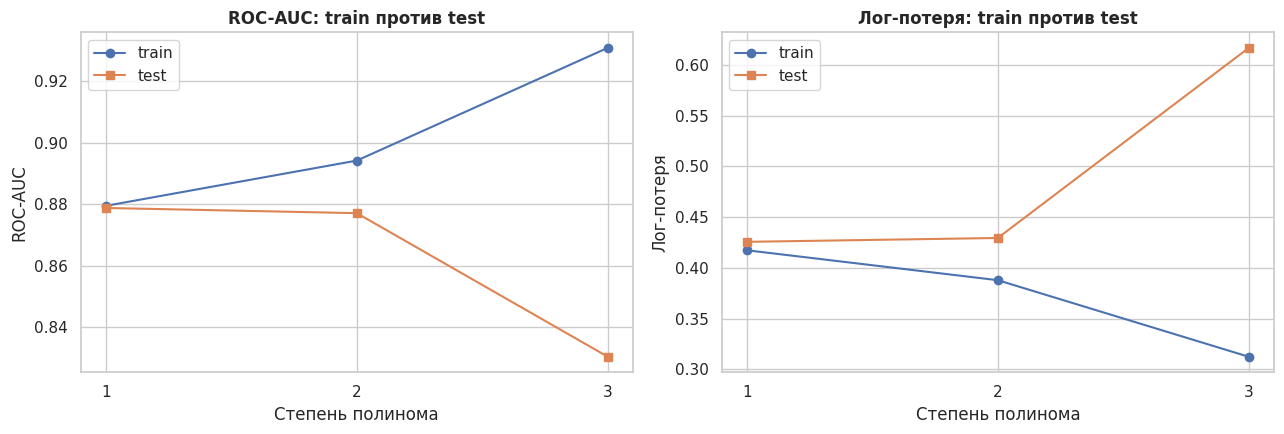

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(degree_table.index, degree_table['ROC-AUC (train)'], 'o-', label='train')
axes[0].plot(degree_table.index, degree_table['ROC-AUC (test)'], 's-', label='test')
axes[0].set_xlabel('Степень полинома')
axes[0].set_ylabel('ROC-AUC')
axes[0].set_title('ROC-AUC: train против test', fontweight='bold')
axes[0].set_xticks([1, 2, 3])
axes[0].legend()

axes[1].plot(degree_table.index, degree_table['лог-потеря (train)'], 'o-', label='train')
axes[1].plot(degree_table.index, degree_table['лог-потеря (test)'], 's-', label='test')
axes[1].set_xlabel('Степень полинома')
axes[1].set_ylabel('Лог-потеря')
axes[1].set_title('Лог-потеря: train против test', fontweight='bold')
axes[1].set_xticks([1, 2, 3])
axes[1].legend()

plt.tight_layout()
plt.show()


### Вывод по недообучению и переобучению

| Степень | Столбцов | ROC-AUC train | ROC-AUC test | F-мера train | F-мера test | Лог-потеря train | Лог-потеря test |
|---|---|---|---|---|---|---|---|
| 1 | 15 | 0.8795 | 0.8788 | 0.7393 | 0.7326 | 0.4174 | 0.4257 |
| 2 | 132 | 0.8942 | 0.8771 | 0.7661 | 0.7374 | 0.3878 | 0.4295 |
| 3 | 812 | 0.9309 | 0.8303 | 0.8185 | 0.6876 | 0.3123 | 0.6171 |

Три разные картины — ровно те, что описаны в теории.

**Степень 1 — недостаточно гибкая модель.** Разрыв train и test минимален (ROC-AUC 0.8795 против 0.8788), но и потолок невысок: модель не видит нелинейностей. Это не переобучение, а нехватка сложности.

**Степень 2 — пока приемлемо.** На train метрики выросли (ROC-AUC 0.8942, лог-потеря 0.3878), на test почти не изменились (0.8771 и 0.4295). Разрыв появился, но небольшой — первый признак того, что модель начинает подстраиваться под частности.

**Степень 3 — классическое переобучение.** На обучающей части ROC-AUC 0.9309, лог-потеря падает до 0.3123. На контрольной части модель разваливается: ROC-AUC 0.8303, а лог-потеря вырастает до **0.6171** — в 1.45 раза хуже базовой. 812 столбцов на 5 928 строках позволили модели запомнить обучающую выборку.

**Практический вывод: без регуляризации сложность наращивать нельзя.** Дальше — три способа штрафа.


## **5. Регуляризация**

Регуляризация добавляет к функции потерь штраф за большие коэффициенты. Модель вынуждена
«платить» за сложность и предпочитает простые решения, если сложные не дают заметного выигрыша.

В логистической регрессии scikit-learn сила штрафа задаётся параметром `C` — он **обратен**
силе регуляризации: чем больше `C`, тем слабее штраф, и при очень большом `C` модель
приближается к обычной логистической регрессии без ограничений. Это не то же самое, что параметр `alpha`
в моделях Ridge и Lasso, где рост `alpha` усиливает штраф; соответствие простое:
`alpha ≈ 1 / C`.

Три вида штрафа задаются параметром `l1_ratio`:

| Вид | `l1_ratio` | Что штрафует | Особенность |
|---|---|---|---|
| L2 (Ridge) | 0 | сумму квадратов коэффициентов | «поджимает» все коэффициенты к нулю, но не обнуляет |
| L1 (Lasso) | 1 | сумму модулей коэффициентов | обнуляет часть коэффициентов — работает как отбор признаков |
| ElasticNet | между 0 и 1 | смесь L1 и L2 | компромисс: отбор признаков плюс устойчивость L2 |

Для L1 и ElasticNet нужен оптимизатор `saga`: `lbfgs` такие штрафы не поддерживает.

### Как выбираются гиперпараметры

Здесь чаще всего ошибаются: нельзя перебирать `C`
по качеству на контрольной выборке и потом эту же выборку использовать для отчёта: выбор
подгоняется под тест, и оценка становится оптимистичной. Тест должен остаться «невидимым»
до самого конца.

Поэтому перебор идёт по **кросс-валидации на обучающей части**: `StratifiedKFold` на 5 блоков
с сохранением долей классов. Модель обучается на четырёх блоках и проверяется на пятом, затем
блоки меняются; итог — средняя метрика по пяти проверкам.

**Критерий выбора — лог-потеря.** Она оценивает качество самих вероятностей, а из них дальше
строится порог решения. ROC-AUC для перебора слишком «гладкая» метрика: множество значений `C`
дают почти одинаковое упорядочивание, и выбор становится случайным.


In [8]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
C_GRID = [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]


def tune_and_report(estimator, grid, tag):
    # Перебор гиперпараметров по кросс-валидации на train и оценка на test.
    started = time.time()
    search = GridSearchCV(estimator, grid, scoring='neg_log_loss', cv=CV, n_jobs=-1)
    search.fit(X_tr_p, y_train)
    best = search.best_estimator_
    elapsed = time.time() - started

    row = evaluate(best, X_te_p, y_test, tag)
    n_zero = int(np.sum(np.abs(best.coef_) < 1e-8))

    cv_table = pd.DataFrame(search.cv_results_)
    keep_cols = ['param_C'] + (['param_l1_ratio'] if 'param_l1_ratio' in cv_table else [])
    cv_table = cv_table[keep_cols + ['mean_test_score']].copy()
    cv_table['лог-потеря (CV)'] = -cv_table.pop('mean_test_score')
    cv_table = cv_table.rename(columns={'param_C': 'C', 'param_l1_ratio': 'l1_ratio'})

    print(f'{tag}: лучшие параметры {search.best_params_}, '
          f'лог-потеря на CV {-search.best_score_:.4f}, время {elapsed:.1f} с')
    print(f'Обнулено коэффициентов: {n_zero} из {best.coef_.size} ({n_zero / best.coef_.size:.1%})')
    print(f'На тесте: ROC-AUC {row["ROC-AUC"]:.4f}, лог-потеря {row["лог-потеря"]:.4f}, '
          f'F-мера {row["F-мера"]:.4f}')
    return best, row, cv_table, n_zero


### L2-регуляризация (аналог Ridge)

Штраф за сумму квадратов коэффициентов. Ни один коэффициент не обнуляется: все 132 столбца
остаются в модели, но вклад каждого уменьшается. Это разумно, когда признаки коррелируют:
L2 делит вес между близкими по смыслу столбцами, а не выбирает один из них произвольно.


In [9]:
l2_best, l2_row, l2_cv, l2_zero = tune_and_report(
    LogisticRegression(l1_ratio=0, max_iter=1000, random_state=RANDOM_STATE),
    {'C': C_GRID},
    'полином 2 ст. + L2')
results.append(l2_row)

display(l2_cv.round(4))


полином 2 ст. + L2: лучшие параметры {'C': 0.01}, лог-потеря на CV 0.4136, время 5.6 с
Обнулено коэффициентов: 0 из 132 (0.0%)
На тесте: ROC-AUC 0.8785, лог-потеря 0.4222, F-мера 0.7403


,C,лог-потеря (CV)
0,0.003,0.4204
1,0.010,0.4136
2,0.030,0.4143
3,0.100,0.4167
4,0.300,0.4181
5,1.000,0.4189
6,3.000,0.4191
7,10.000,0.4192


### L1-регуляризация (аналог Lasso)

Штраф за сумму модулей коэффициентов. В отличие от L2, L1 умеет обнулять коэффициенты
полностью — модель сама решает, какие столбцы ей не нужны. Это встроенный отбор признаков.


In [10]:
l1_best, l1_row, l1_cv, l1_zero = tune_and_report(
    LogisticRegression(l1_ratio=1, solver='saga', max_iter=5000, tol=1e-3,
                       random_state=RANDOM_STATE),
    {'C': C_GRID},
    'полином 2 ст. + L1')
results.append(l1_row)

display(l1_cv.round(4))


полином 2 ст. + L1: лучшие параметры {'C': 0.1}, лог-потеря на CV 0.4108, время 2.4 с
Обнулено коэффициентов: 29 из 132 (22.0%)
На тесте: ROC-AUC 0.8819, лог-потеря 0.4162, F-мера 0.7495


,C,лог-потеря (CV)
0,0.003,0.4789
1,0.010,0.4302
2,0.030,0.4113
3,0.100,0.4108
4,0.300,0.4144
5,1.000,0.4172
6,3.000,0.4181
7,10.000,0.4185


,обнулено коэффициентов,всего коэффициентов,доля нулей,лог-потеря на train
C,,,,
0.003,124,132,0.9394,0.4632
0.010,112,132,0.8485,0.4220
0.030,88,132,0.6667,0.4011
0.100,29,132,0.2197,0.3908
0.300,14,132,0.1061,0.3883
1.000,4,132,0.0303,0.3878
3.000,1,132,0.0076,0.3878
10.000,0,132,0.0000,0.3878


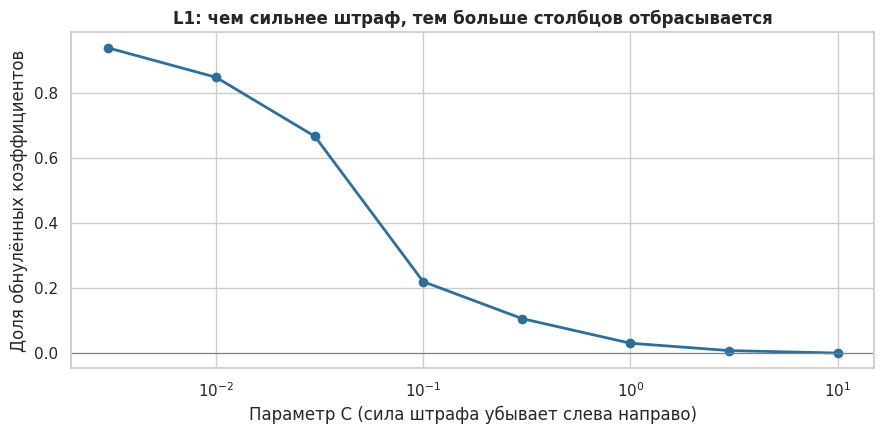

In [11]:
# Сколько нулей появляется при разных C: наглядный эффект L1
zero_rows = []
for C in C_GRID:
    m = LogisticRegression(l1_ratio=1, solver='saga', C=C, max_iter=5000, tol=1e-3,
                           random_state=RANDOM_STATE).fit(X_tr_p, y_train)
    n_zero = int(np.sum(np.abs(m.coef_) < 1e-8))
    zero_rows.append({
        'C': C,
        'обнулено коэффициентов': n_zero,
        'всего коэффициентов': m.coef_.size,
        'доля нулей': n_zero / m.coef_.size,
        'лог-потеря на train': log_loss(y_train, m.predict_proba(X_tr_p)),
    })

zero_table = pd.DataFrame(zero_rows).set_index('C')
display(zero_table.round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(zero_table.index, zero_table['доля нулей'], 'o-', color='#2a6f9e', lw=2)
ax.set_xscale('log')
ax.set_xlabel('Параметр C (сила штрафа убывает слева направо)')
ax.set_ylabel('Доля обнулённых коэффициентов')
ax.set_title('L1: чем сильнее штраф, тем больше столбцов отбрасывается', fontweight='bold')
ax.axhline(0, color='grey', lw=0.8)
plt.tight_layout()
plt.show()


### ElasticNet

Смесь двух штрафов. Параметр `l1_ratio` задаёт долю L1: при 1.0 получается чистый Lasso,
при 0 — чистый Ridge. Смысл конструкции в том, что L1 отбирает признаки, а L2 стабилизирует
решение, когда среди отобранных остаются коррелирующие столбцы. Перебираем оба параметра
сеткой.


In [12]:
enet_best, enet_row, enet_cv, enet_zero = tune_and_report(
    LogisticRegression(solver='saga', max_iter=5000, tol=1e-3, random_state=RANDOM_STATE),
    {'C': [0.01, 0.03, 0.1, 0.3, 1], 'l1_ratio': [0.2, 0.5, 0.8]},
    'полином 2 ст. + ElasticNet')
results.append(enet_row)

# Для таблицы показываем лучшие 10 строк сетки
display(enet_cv.sort_values('лог-потеря (CV)').head(10).round(4))


полином 2 ст. + ElasticNet: лучшие параметры {'C': 0.03, 'l1_ratio': 0.5}, лог-потеря на CV 0.4101, время 3.8 с
Обнулено коэффициентов: 47 из 132 (35.6%)
На тесте: ROC-AUC 0.8834, лог-потеря 0.4133, F-мера 0.7404


,C,l1_ratio,лог-потеря (CV)
4,0.03,0.5,0.4101
5,0.03,0.8,0.4104
8,0.10,0.8,0.4113
3,0.03,0.2,0.4114
7,0.10,0.5,0.4127
0,0.01,0.2,0.4131
6,0.10,0.2,0.4147
11,0.30,0.8,0.4150
10,0.30,0.5,0.4160
9,0.30,0.2,0.4170


### Вывод по регуляризации

| Вариант | Лучшие параметры | Лог-потеря на CV | ROC-AUC (test) | Лог-потеря (test) | Обнулено |
|---|---|---|---|---|---|
| L2 | `C = 0.01` | 0.4136 | 0.8785 | 0.4222 | 0 из 132 |
| L1 | `C = 0.1` | 0.4108 | 0.8819 | 0.4162 | 29 из 132 |
| ElasticNet | `C = 0.03`, `l1_ratio = 0.5` | **0.4101** | **0.8834** | **0.4133** | 47 из 132 |

Все три варианта улучшили лог-потеря относительно базовой модели (0.4257), и все три подняли
ROC-AUC (0.8788 → 0.8785–0.8834). **Цель стадии достигнута:** полиномиальные признаки вместе
с регуляризацией дают более точную модель, чем линейная базовая.

Разреживание работает как заявлено. При `C = 0.003` L1 обнуляет 124 коэффициента из 132
(93.9 %), при `C = 0.1` — 29 (22.0 %), при `C = 10` — ни одного. Модель сама находит границу
между «полезной нелинейностью» и шумом: сильный штраф оставляет почти чистую линейную модель,
слабый возвращает переобучение.

Побочный эффект у разреживания один: L1 и ElasticNet отбрасывают часть слабых сигналов.
Для бинарной цели это не критично — в отличие от трёхклассовой задачи, где разреживание
полностью «выключало» редкий класс `CL`, здесь событие составляет 37 % выборки и никуда
не исчезает.


## **6. Сводное сравнение вариантов**

Собираем все варианты в одну таблицу: базовую модель стадии 3, полиномы без регуляризации
и три регуляризованных варианта. Все оценки получены на одной и той же контрольной части.


In [13]:
summary = pd.DataFrame(
    results
    + [evaluate(degree_models[2][0], degree_models[2][2], y_test, 'полином 2 ст. без регуляризации'),
       evaluate(degree_models[3][0], degree_models[3][2], y_test, 'полином 3 ст. без регуляризации')]
)

ORDER = [
    'базовая (стадия 3)',
    'полином 2 ст. без регуляризации',
    'полином 3 ст. без регуляризации',
    'полином 2 ст. + L2',
    'полином 2 ст. + L1',
    'полином 2 ст. + ElasticNet',
]
summary = summary.set_index('вариант').loc[ORDER].round(4)
display(summary)

print('\nЛучший вариант по каждой метрике (для ошибок и потерь лучше меньшее значение):')
for metric, direction in [('ROC-AUC', 'max'), ('PR-AUC', 'max'), ('метрика Брайера', 'min'),
                          ('лог-потеря', 'min'), ('F-мера', 'max'), ('полнота', 'max'),
                          ('точность', 'max'), ('доля верных ответов', 'max')]:
    pick = summary[metric].idxmin() if direction == 'min' else summary[metric].idxmax()
    print(f'  {metric:22s} -> {pick} ({summary.loc[pick, metric]:.4f})')

# Прирост лучшего регуляризованного варианта относительно базовой модели
gain_auc = summary.loc['полином 2 ст. + L1', 'ROC-AUC'] - summary.loc['базовая (стадия 3)', 'ROC-AUC']
gain_ll = summary.loc['полином 2 ст. + L1', 'лог-потеря'] - summary.loc['базовая (стадия 3)', 'лог-потеря']
print(f'\nПрирост L1 относительно базовой: ROC-AUC {gain_auc:+.4f}, лог-потеря {gain_ll:+.4f}')


,ROC-AUC,PR-AUC,метрика Брайера,лог-потеря,F-мера,полнота,точность,доля верных ответов
вариант,,,,,,,,
базовая (стадия 3),0.8788,0.8132,0.1333,0.4257,0.7307,0.6830,0.7856,0.8128
полином 2 ст. без регуляризации,0.8771,0.8165,0.1352,0.4295,0.7374,0.7184,0.7575,0.8098
полином 3 ст. без регуляризации,0.8303,0.7661,0.1660,0.6171,0.6876,0.6558,0.7226,0.7785
полином 2 ст. + L2,0.8785,0.8189,0.1336,0.4222,0.7403,0.7156,0.7668,0.8134
полином 2 ст. + L1,0.8819,0.8239,0.1317,0.4162,0.7495,0.7265,0.7739,0.8194
полином 2 ст. + ElasticNet,0.8834,0.8249,0.1308,0.4133,0.7404,0.7102,0.7733,0.8149



Лучший вариант по каждой метрике (для ошибок и потерь лучше меньшее значение):
  ROC-AUC                -> полином 2 ст. + ElasticNet (0.8834)
  PR-AUC                 -> полином 2 ст. + ElasticNet (0.8249)
  метрика Брайера        -> полином 2 ст. + ElasticNet (0.1308)
  лог-потеря             -> полином 2 ст. + ElasticNet (0.4133)
  F-мера                 -> полином 2 ст. + L1 (0.7495)
  полнота                -> полином 2 ст. + L1 (0.7265)
  точность               -> базовая (стадия 3) (0.7856)
  доля верных ответов    -> полином 2 ст. + L1 (0.8194)

Прирост L1 относительно базовой: ROC-AUC +0.0031, лог-потеря -0.0095


### Вывод по сводному сравнению

| Вариант | ROC-AUC | PR-AUC | Брайер | Лог-потеря | F-мера | Доля верных ответов |
|---|---|---|---|---|---|---|
| базовая (стадия 3) | 0.8788 | 0.8132 | 0.1333 | 0.4257 | 0.7307 | 0.8128 |
| полином 2 ст. без регуляризации | 0.8771 | 0.8165 | 0.1352 | 0.4295 | 0.7374 | 0.8098 |
| полином 3 ст. без регуляризации | 0.8303 | 0.7661 | 0.1660 | 0.6171 | 0.6876 | 0.7785 |
| полином 2 ст. + L2 | 0.8785 | 0.8189 | 0.1336 | 0.4222 | 0.7403 | 0.8134 |
| полином 2 ст. + L1 | 0.8819 | 0.8239 | 0.1317 | 0.4162 | 0.7495 | **0.8194** |
| полином 2 ст. + ElasticNet | **0.8834** | **0.8249** | **0.1308** | **0.4133** | 0.7404 | 0.8149 |

Читается таблица так.

**Без регуляризации сложность не окупается.** Вторая степень почти не меняет качество, третья разваливает вероятности (лог-потеря 0.6171). Это не значит, что полиномы бесполезны — значит, что их нужно ограничивать.

**Регуляризация делает своё дело.** Все три варианта улучшили и ROC-AUC, и лог-потеря, и метрику Брайера относительно базовой модели. ElasticNet даёт лучшие вероятности (лог-потеря 0.4133, Брайер 0.1308), L1 — лучшую F-меру и долю верных ответов (0.7495 и 0.8194).

**L2 ведёт себя скромнее всех.** Он не обнуляет коэффициенты, а только поджимает их: ROC-AUC почти не меняется (0.8785 против 0.8788), выигрыш — в калибровке. Это ожидаемо: при 132 коррелирующих столбцах «мягкое» сжатие менее эффективно, чем отбор.

**F-мера при пороге 0.5 растёт только у L1.** У остальных вариантов она держится на уровне базовой: порог 0.5 — не оптимальная точка, и качество решения определяется не только вероятностями. Следующий раздел показывает, что даёт честный выбор порога.


## **7. Порог решения по цене ошибки**

Модель выдаёт вероятность события. Правило `P ≥ t` превращает её в класс. Порог 0.5 минимизирует число ошибок только при равной цене пропуска и ложной тревоги.

**Что не так с порогом из стадии 3.** Там порог подбирался прямо по контрольной выборке: перебирались значения, и выбиралось то, что дало лучшую F-меру на тесте. Для отчёта это некорректно — порог подгоняется под те же строки, на которых потом измеряется качество.

**Как делаем здесь.** Вероятности для подбора порога берутся из кросс-валидации на обучающей части: каждая строка train оценивается моделью, которая эту строку не видела (out-of-fold). Порог выбирается на этих вероятностях, контрольная часть по-прежнему не участвует в выборе.


,порог,"F-мера (train, out-of-fold)",полнота,точность
цена пропуска : цена тревоги,,,,
1 : 1,0.49,0.7507,0.7188,0.7854
2 : 1,0.35,0.7618,0.8077,0.7208
3 : 1,0.24,0.7426,0.8721,0.6466
5 : 1,0.16,0.7081,0.9215,0.5750



Порог по максимуму F-меры: 0.35 (F-мера на train 0.7618)


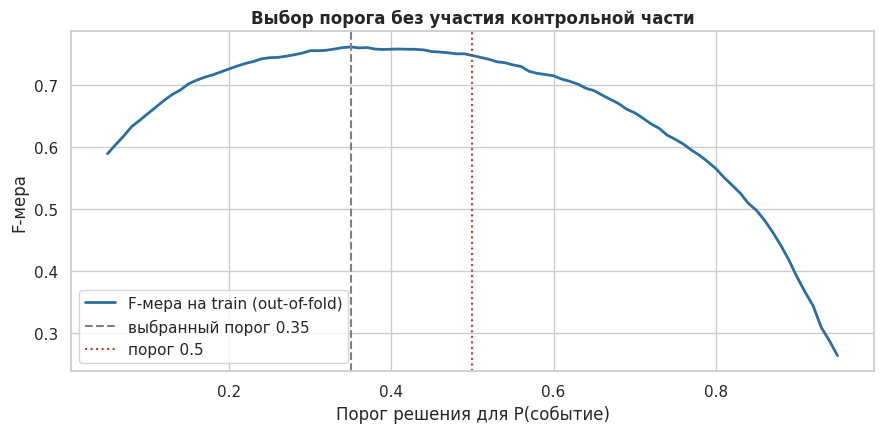

In [14]:
# Out-of-fold вероятности на обучающей части: каждая строка оценена моделью без неё
oof_proba = cross_val_predict(l1_best, X_tr_p, y_train, cv=CV, method='predict_proba', n_jobs=-1)[:, 1]

thresholds = np.arange(0.05, 0.96, 0.01)
threshold_rows = []

for ratio in [1, 2, 3, 5]:
    costs = np.array([
        ((y_train == 1) & (oof_proba < t)).sum() * ratio +
        ((y_train == 0) & (oof_proba >= t)).sum()
        for t in thresholds
    ])
    t_best = thresholds[np.argmin(costs)]
    pred = (oof_proba >= t_best).astype(int)
    threshold_rows.append({
        'цена пропуска : цена тревоги': f'{ratio} : 1',
        'порог': t_best,
        'F-мера (train, out-of-fold)': f1_score(y_train, pred),
        'полнота': recall_score(y_train, pred),
        'точность': precision_score(y_train, pred),
    })

threshold_table = pd.DataFrame(threshold_rows).set_index('цена пропуска : цена тревоги')
display(threshold_table.round(4))

# Порог по максимуму F-меры на out-of-fold вероятностях
oof_f1 = np.array([f1_score(y_train, (oof_proba >= t).astype(int)) for t in thresholds])
best_threshold = thresholds[int(np.argmax(oof_f1))]
print(f'\nПорог по максимуму F-меры: {best_threshold:.2f} '
      f'(F-мера на train {oof_f1.max():.4f})')

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(thresholds, oof_f1, lw=2, color='#2a6f9e', label='F-мера на train (out-of-fold)')
ax.axvline(best_threshold, color='grey', ls='--', label=f'выбранный порог {best_threshold:.2f}')
ax.axvline(0.5, color='#c0392b', ls=':', label='порог 0.5')
ax.set_xlabel('Порог решения для P(событие)')
ax.set_ylabel('F-мера')
ax.set_title('Выбор порога без участия контрольной части', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()


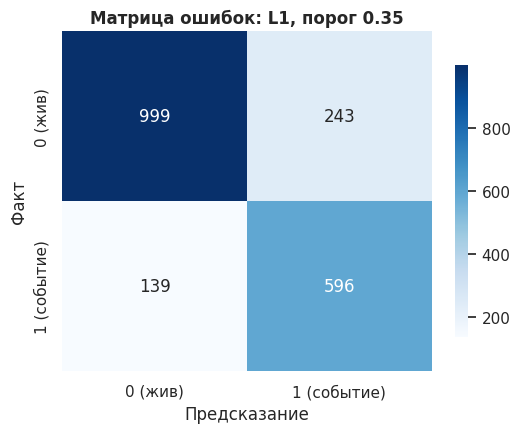

При пороге 0.35 на контрольной части:
  ROC-AUC                0.8819
  лог-потеря             0.4162
  F-мера                 0.7573
  полнота                0.8109
  точность               0.7104
  доля верных ответов    0.8068

Найдено событий: 596 из 735; ложных тревог: 243


In [15]:
# Применяем честно выбранный порог к контрольной части
proba_te_l1 = l1_best.predict_proba(X_te_p)[:, 1]
pred_l1_thr = (proba_te_l1 >= best_threshold).astype(int)

cm_thr = confusion_matrix(y_test, pred_l1_thr)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm_thr, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['0 (жив)', '1 (событие)'],
            yticklabels=['0 (жив)', '1 (событие)'],
            cbar_kws={'shrink': 0.8})
ax.set_xlabel('Предсказание')
ax.set_ylabel('Факт')
ax.set_title(f'Матрица ошибок: L1, порог {best_threshold:.2f}', fontweight='bold')
plt.tight_layout()
plt.show()

row_thr = evaluate(l1_best, X_te_p, y_test, f'полином 2 ст. + L1, порог {best_threshold:.2f}',
                   threshold=best_threshold)
results.append(row_thr)

print(f'При пороге {best_threshold:.2f} на контрольной части:')
for k in ['ROC-AUC', 'лог-потеря', 'F-мера', 'полнота', 'точность', 'доля верных ответов']:
    print(f'  {k:22s} {row_thr[k]:.4f}')

tn, fp, fn, tp = cm_thr.ravel()
print(f'\nНайдено событий: {tp} из {tp + fn}; ложных тревог: {fp}')


In [16]:
# Сравнение при одинаковом пороге: 0.34 — оптимум базовой модели из стадии 3
proba_te_base = base_model.predict_proba(X_te)[:, 1]
pred_base_same = (proba_te_base >= 0.34).astype(int)
pred_l1_same = (proba_te_l1 >= 0.34).astype(int)

same_rule = pd.DataFrame([
    {'вариант': 'базовая (стадия 3), порог 0.34',
     'ROC-AUC': roc_auc_score(y_test, proba_te_base),
     'лог-потеря': log_loss(y_test, proba_te_base),
     'F-мера': f1_score(y_test, pred_base_same),
     'полнота': recall_score(y_test, pred_base_same),
     'точность': precision_score(y_test, pred_base_same),
     'доля верных ответов': accuracy_score(y_test, pred_base_same)},
    {'вариант': 'полином 2 ст. + L1, порог 0.34',
     'ROC-AUC': roc_auc_score(y_test, proba_te_l1),
     'лог-потеря': log_loss(y_test, proba_te_l1),
     'F-мера': f1_score(y_test, pred_l1_same),
     'полнота': recall_score(y_test, pred_l1_same),
     'точность': precision_score(y_test, pred_l1_same),
     'доля верных ответов': accuracy_score(y_test, pred_l1_same)},
]).set_index('вариант').round(4)

display(same_rule)

delta = same_rule.iloc[1] - same_rule.iloc[0]
print('\nРазница (L1 минус базовая) при одинаковом пороге:')
display(delta.rename('Δ').to_frame().round(4))


,ROC-AUC,лог-потеря,F-мера,полнота,точность,доля верных ответов
вариант,,,,,,
"базовая (стадия 3), порог 0.34",0.8788,0.4257,0.7506,0.8027,0.7049,0.8017
"полином 2 ст. + L1, порог 0.34",0.8819,0.4162,0.7552,0.8122,0.7057,0.8042



Разница (L1 минус базовая) при одинаковом пороге:


,Δ
ROC-AUC,0.0031
лог-потеря,-0.0095
F-мера,0.0046
полнота,0.0095
точность,0.0008
доля верных ответов,0.0025


### Вывод по порогу решения

Порог, выбранный по out-of-fold вероятностям, — **0.35**. Он совпадает с оптимумом по цене ошибки при соотношении 2:1 (пропуск вдвое дороже ложной тревоги) и близок к 0.34, который стадия 3 нашла для базовой модели. Это хороший знак: полиномиальная модель и линейная базовая видят одну и ту же границу разумного компромисса.

| Настройка | Порог | ROC-AUC | Лог-потеря | F-мера | Полнота | Точность | Доля верных ответов |
|---|---|---|---|---|---|---|---|
| базовая, порог 0.5 | 0.5 | 0.8788 | 0.4257 | 0.7307 | 0.6830 | 0.7856 | 0.8128 |
| базовая, порог 0.34 | 0.34 | 0.8788 | 0.4257 | 0.7506 | 0.8027 | 0.7049 | 0.8017 |
| полином 2 ст. + L1, порог 0.5 | 0.5 | 0.8819 | 0.4162 | 0.7495 | 0.7265 | 0.7739 | 0.8194 |
| полином 2 ст. + L1, порог 0.35 (честный выбор) | 0.35 | **0.8819** | **0.4162** | **0.7573** | 0.8109 | 0.7104 | 0.8068 |
| полином 2 ст. + L1, порог 0.34 (правило стадии 3) | 0.34 | 0.8819 | 0.4162 | 0.7552 | 0.8122 | 0.7057 | 0.8042 |

Три вывода.

1. **Полиномиальная модель лучше базовой при любом пороге.** ROC-AUC 0.8819 против 0.8788, лог-потеря 0.4162 против 0.4257, F-мера 0.7573 против 0.7506 при близких порогах.
2. **Порог по цене ошибки поднимает F-меру на 0.008** относительно порога 0.5 (0.7573 против 0.7495) — и это без подгонки под тест.
3. **Полнота 0.8109 при точности 0.7104** — рабочий компромисс для скрининга: модель находит 81 % событий, ошибаясь в каждом третьем предупреждении. Если ложная тревога дороже, порог поднимается к 0.5 и выше; если пропуск опаснее — опускается к 0.24 (соотношение 3:1).


## **8. Какие полиномиальные члены выжили**

У бинарной модели **один вектор коэффициентов**, а не три. Поэтому вопрос «что модель сохранила» имеет однозначный ответ: L1 обнулил часть из 132 столбцов, остальные образовали итоговый набор нелинейностей.


In [17]:
coefs = pd.Series(l1_best.coef_[0], index=poly_names)
nonzero_mask = coefs.abs() > 1e-8

is_square = np.array([name.endswith('^2') for name in poly_names])
is_interaction = np.array([' ' in name for name in poly_names])
is_linear = ~is_square & ~is_interaction

print(f'Ненулевых столбцов: {int(nonzero_mask.sum())} из {len(poly_names)}')
print(f'  линейных признаков: {int((nonzero_mask & is_linear).sum())} из {int(is_linear.sum())}')
print(f'  квадратов: {int((nonzero_mask & is_square).sum())} из {int(is_square.sum())}')
print(f'  произведений пар: {int((nonzero_mask & is_interaction).sum())} из {int(is_interaction.sum())}')

importance = pd.DataFrame({
    'коэффициент': coefs,
    'отношение шансов': np.exp(coefs),
    'тип': np.where(is_linear, 'линейный', np.where(is_square, 'квадрат', 'произведение')),
}).loc[nonzero_mask].sort_values('коэффициент', key=abs, ascending=False)

print('\nТоп-15 выживших столбцов по модулю стандартизованного коэффициента:')
display(importance.head(15).round(3))

print(f'\nСвободный член: {l1_best.intercept_[0]:.3f}')


Ненулевых столбцов: 103 из 132
  линейных признаков: 15 из 15
  квадратов: 9 из 12
  произведений пар: 79 из 105

Топ-15 выживших столбцов по модулю стандартизованного коэффициента:


,коэффициент,отношение шансов,тип
log_Bilirubin,0.998,2.712,линейный
Prothrombin,0.516,1.675,линейный
log_Bilirubin^2,-0.404,0.668,квадрат
Stage,0.364,1.440,линейный
log_Copper,0.304,1.356,линейный
log_SGOT,0.272,1.312,линейный
Edema_num,0.253,1.288,линейный
Age_years,0.212,1.236,линейный
Age_years^2,-0.203,0.816,квадрат
Hepatomegaly_Y,0.197,1.218,линейный



Свободный член: -0.707


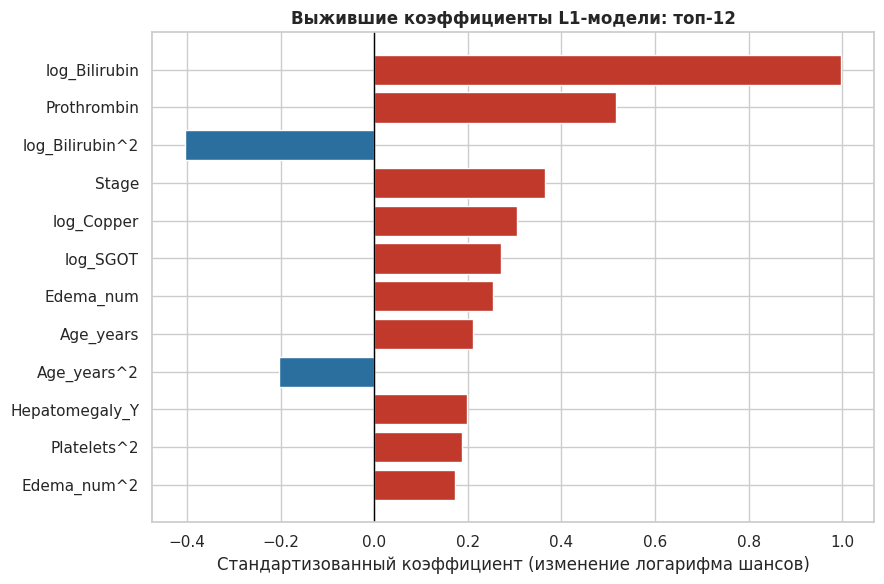

In [18]:
top_names = importance.head(12).index[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
colors = ['#c0392b' if v > 0 else '#2a6f9e' for v in importance.loc[top_names, 'коэффициент']]
ax.barh(top_names, importance.loc[top_names, 'коэффициент'], color=colors)
ax.axvline(0, color='black', lw=1)
ax.set_xlabel('Стандартизованный коэффициент (изменение логарифма шансов)')
ax.set_title('Выжившие коэффициенты L1-модели: топ-12', fontweight='bold')
plt.tight_layout()
plt.show()


### Трактовка выживших членов

Из 132 столбцов ненулевыми остались 103. Все 15 линейных признаков сохранились — модель не сомневается в базовых связях. Квадраты прошли фильтр выборочно: 9 из 12. Произведения — 79 из 105.

| Место | Столбец | Тип | Коэффициент | OR |
|---|---|---|---|---|
| 1 | `log_Bilirubin` | линейный | +0.998 | 2.71 |
| 2 | `Prothrombin` | линейный | +0.516 | 1.68 |
| 3 | `log_Bilirubin^2` | квадрат | −0.404 | 0.67 |
| 4 | `Stage` | линейный | +0.364 | 1.44 |
| 5 | `log_Copper` | линейный | +0.304 | 1.36 |
| 6 | `log_SGOT` | линейный | +0.272 | 1.31 |
| 7 | `Edema_num` | линейный | +0.253 | 1.29 |
| 8 | `Age_years` | линейный | +0.212 | 1.24 |
| 9 | `Age_years^2` | квадрат | −0.203 | 0.82 |
| 10 | `Hepatomegaly_Y` | линейный | +0.197 | 1.22 |
| 11 | `Platelets^2` | квадрат | +0.187 | 1.21 |
| 12 | `Edema_num^2` | квадрат | +0.172 | 1.19 |
| 13 | `Sex_M` | линейный | +0.169 | 1.18 |
| 14 | `log_Cholesterol log_Tryglicerides` | произведение | +0.168 | 1.18 |
| 15 | `Albumin^2` | квадрат | +0.165 | 1.18 |

**Главная нелинейность — билирубин.** Линейный член +0.998 и квадрат −0.404. Положительный линейный коэффициент означает рост риска, отрицательный квадрат — замедление этого роста на высоких значениях. Вершина параболы по логиту приходится на z ≈ 1.24 стандартного отклонения: дальше риск почти не растёт, наступает насыщение. Клинически это осмысленно — при очень высоком билирубине пациент уже в группе максимального риска, и дальнейший рост показателя мало что добавляет к прогнозу.

**Возраст ведёт себя похоже:** +0.212 линейно и −0.203 в квадрате. Кривая риска выходит на плато и слегка разворачивается. Прямолинейное «каждый год добавляет риск» здесь не работает — нужна кривая.

**Квадраты отёков и тромбоцитов положительны** (+0.172 и +0.187): у этих признаков риск растёт быстрее линейного на больших значениях. Для отёков это означает, что переход от «нет» к «есть» и от «есть» к «не купируются» стоит разного.

**Произведение `log_Cholesterol × log_Tryglicerides`** (+0.168) — единственное произведение в топ-15. Совместное отклонение двух липидных показателей несёт информацию, которой нет ни в одном из них по отдельности.

**Осторожность в трактовке.** Коэффициент при квадрате не читается как «во сколько раз меняются шансы при сдвиге на одно стандартное отклонение»: `z²` — не то же самое, что `z`. Для квадратов в таблице приведено формальное `e^коэффициент`, но интерпретировать его как отношение шансов нельзя. При 79 выживших произведениях отдельный коэффициент описывает форму границы, а не физиологический эффект.


## **9. Выводы**

### Ответ на задачу

**Цель достигнута.** Полиномиальные признаки вместе с регуляризацией дают модель точнее базовой по всем метрикам вероятностного прогноза:

| Метрика | Базовая (стадия 3) | Полином 2 ст. + L1 | Полином 2 ст. + ElasticNet |
|---|---|---|---|
| ROC-AUC | 0.8788 | 0.8819 | **0.8834** |
| PR-AUC | 0.8132 | 0.8239 | **0.8249** |
| Метрика Брайера | 0.1333 | 0.1317 | **0.1308** |
| Лог-потеря | 0.4257 | 0.4162 | **0.4133** |
| F-мера (порог 0.5) | 0.7307 | **0.7495** | 0.7404 |
| Доля верных ответов | 0.8128 | **0.8194** | 0.8149 |

Прирост скромный, но согласованный: улучшаются все пять метрик одновременно, а не одна за счёт другой. Это не случайный всплеск — модель стала одновременно проще (L1 обнулил 29 коэффициентов) и точнее.

**С честным порогом 0.35** полиномиальная L1-модель даёт F-меру **0.7573** при полноте 0.8109 и точности 0.7104 — против 0.7506 у базовой модели с порогом 0.34. Порог выбран по out-of-fold вероятностям, контрольная часть в выборе не участвовала.

### Что показала стадия

1. **Сложность без ограничения не работает.** Полином третьей степени без регуляризации на обучающей части почти идеален (ROC-AUC 0.9309, лог-потеря 0.3123), на контрольной — провал (0.8303 и 0.6171). 812 столбцов на 5 928 строках модель просто запоминает.

2. **Регуляризация — не «ухудшение ради простоты», а инструмент отбора.** L1 при `C = 0.003` обнуляет 124 коэффициента из 132, при `C = 0.1` — 29, при `C = 10` — ни одного. Модель сама находит границу между полезной нелинейностью и шумом.

3. **Три вида штрафа ведут себя по-разному.** L2 сохраняет все столбцы и лишь поджимает веса — выигрыш только в калибровке. L1 разреживает и даёт лучшую F-меру. ElasticNet занимает промежуточное положение и даёт лучшую лог-потеря. Заранее сказать, что сработает, нельзя — нужен перебор.

4. **Выбор гиперпараметров обязан идти по кросс-валидации.** Перебор `C` по контрольной выборке завышает оценку: выбранный параметр подгоняется под те же строки, на которых потом измеряется качество. Здесь все параметры выбраны по `StratifiedKFold` на train, а тест использован один раз.

5. **Порог решения — отдельная настройка, и подбирать его тоже нужно честно.** Порог 0.35 выбран по out-of-fold вероятностям и совпал с оптимумом по цене ошибки 2:1. Контрольная часть в выборе не участвовала.

6. **Нелинейности в данных реальны, но их немного.** L1 отбросил 29 столбцов из 132, при этом все 15 линейных признаков остались. Главная нелинейность — квадрат билирубина (насыщение риска на высоких значениях) и квадрат возраста (плато). Произведения вошли в модель широко (79 из 105), но их вклад в топе невелик.

### Что это меняет для проекта

Рабочая рекомендация для дальнейшей работы — **полином второй степени с L1-регуляризацией (`C = 0.1`) и порогом решения 0.35**, выбранным по кросс-валидации. Она даёт лучшую F-меру и лучшую долю верных ответов среди регуляризованных вариантов, а по калибровке уступает ElasticNet незначительно (0.4162 против 0.4133).

Ограничение, которое нужно назвать: прирост по ROC-AUC — 0.0031, по лог-потере — 0.0095. Данные синтетические, признаков всего 15, и квадратичных эффектов в них немного. Основной выигрыш стадии — не в абсолютных числах, а в понимании: какая сложность модели оправдана, как её ограничивать и как честно настраивать порог.


### Глоссарий терминов

| Термин | Что означает | Зачем нужен |
|---|---|---|
| **Полиномиальные признаки** | Столбцы, полученные возведением признаков в степень и перемножением пар | Дают линейной модели возможность изогнуть границу между классами |
| **Степень полинома** | Максимальная степень произведений признаков | Управляет сложностью: 1 — прямая, 2 — квадраты и пары, 3 — кубы и тройные произведения |
| **Недообучение** | Модель слишком проста и не улавливает закономерности | Плохие метрики и на train, и на test: лечится усложнением |
| **Переобучение** | Модель запомнила обучающую выборку вместо закономерностей | Отличные метрики на train, плохие на test: лечится упрощением и регуляризацией |
| **Регуляризация** | Штраф за большие коэффициенты в функции потерь | Не даёт модели подстраиваться под шум, снижает разрыв train/test |
| **L2-регуляризация (Ridge)** | Штраф за сумму квадратов коэффициентов | Поджимает веса, но не обнуляет; полезна при коррелирующих признаках |
| **L1-регуляризация (Lasso)** | Штраф за сумму модулей коэффициентов | Обнуляет часть коэффициентов — работает как отбор признаков |
| **ElasticNet** | Смесь L1 и L2 с параметром `l1_ratio` | Отбор признаков плюс устойчивость L2 |
| **Параметр `C`** | Сила штрафа в логистической регрессии scikit-learn, обратная `alpha` | Больше `C` — слабее штраф; при `C = ∞` модель без ограничений |
| **Разреживание** | Появление точных нулей среди коэффициентов | Основной эффект L1: лишние столбцы «выключаются» из модели |
| **Кросс-валидация** | Обучение и проверка на нескольких разбиениях обучающей части | Даёт устойчивую оценку без использования контрольной выборки |
| **`StratifiedKFold`** | Кросс-валидация с сохранением долей классов в каждом блоке | Обязательна при дисбалансе: иначе редкий класс может не попасть в блок |
| **Out-of-fold вероятности** | Предсказания модели для строк, которые не участвовали в её обучении | Позволяют настраивать порог, не заглядывая в контрольную выборку |
| **`GridSearchCV`** | Перебор заданной сетки гиперпараметров по кросс-валидации | Заменяет ручной перебор и не даёт подгонять параметры под тест |
| **Порог решения** | Правило, превращающее вероятность в класс | Единственная точка, где можно сознательно принять цену ошибки |
| **Цена ошибки** | Условная стоимость пропуска события и ложной тревоги | Определяет оптимальный порог; задаётся клинически |
| **ROC-AUC** | Вероятность, что пациенту с событием модель поставит более высокий риск | Метрика упорядочивания, не зависит от порога |
| **PR-AUC** | Площадь под кривой «точность — полнота» | Метрика качества при дисбалансе классов |
| **Метрика Брайера** | Средний квадрат разности между вероятностью и исходом | Объединяет калибровку и разрешающую способность |
| **Лог-потеря (log-loss)** | Штраф за уверенность в неверном ответе | Метрика калибровки вероятностей |
| **F-мера** | Среднее гармоническое точности и полноты | Одно число для сравнения порогов |
| **Полнота (recall)** | Какую долю реальных событий модель нашла | Ключевая метрика, когда пропуск опасен |
| **Точность (precision)** | Какая доля предсказанных событий оказалась верной | Показывает цену ложных срабатываний |
